# What Drives Resale-Condo Prices in Tokyo?

## Module 24 — Notebook 3 of 3: Model Evaluation and Findings

**Author:** Sumit Mishra

This notebook takes the best-performing model from Notebook 2 and evaluates it in greater detail, focusing on its performance and practical applications.

### What This Notebook Covers

1. Loading the saved model and verifying its performance on the test dataset.
2. Analysing where the model produces more accurate predictions and where it struggles.
3. Identifying the features that have the greatest influence on model predictions.
4. Running what-if scenarios to understand how changes in individual property characteristics affect estimated prices.
5. Using model predictions to identify transactions that may be overpriced or underpriced.
6. Summarising the key findings, practical recommendations, model limitations and possible next steps.

In [1]:
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:,.2f}".format)

DATA_PATH = "../data/processed/tokyo_condos_clean.csv.gz"
MODEL_PATH = "../models/best_model.joblib"
IMAGE_DIR = "../images"
RANDOM_STATE = 42


def show_plotly(fig, name, width=1000, height=520):
    """Save a Plotly chart as PNG (GitHub can't show interactive charts) and display it."""
    path = f"{IMAGE_DIR}/{name}.png"
    try:
        fig.write_image(path, width=width, height=height, scale=2)
        display(Image(path, width=900))
    except Exception:
        fig.show()

## 1. Load the Model and the Test Set

In [2]:
df = (pd.read_csv(DATA_PATH).sort_values("time_index", kind="stable").reset_index(drop=True))
df["nearest_station_jp"] = df["nearest_station_jp"].fillna("Unknown")

NUMERIC_FEATURES = ["area_sqm", "rooms", "building_age", "walk_min", "time_index",
                    "coverage_ratio_pct", "floor_area_ratio_pct", "has_living_dining", "has_storage_room"]
CATEGORICAL_FEATURES = ["municipality", "structure", "zoning", "renovation", "use_recorded"]
LOCATION_FEATURES = ["district_jp", "nearest_station_jp"]
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES + LOCATION_FEATURES

test_df = df[df["trade_year"] > 2023].copy()
saved = joblib.load(MODEL_PATH)


def predict_price(frame):
    """Estimated fair price in yen: model prediction + market trend, converted back from log."""
    log_pred = saved["pipeline"].predict(frame[ALL_FEATURES]) + saved["time_slope"] * frame["time_index"].to_numpy()
    return np.exp(log_pred)


test_df["predicted_price"] = predict_price(test_df)
test_df["error_pct"] = (test_df["predicted_price"] / test_df["price_yen"] - 1) * 100   # + = estimate above sale price
test_df["abs_error_pct"] = test_df["error_pct"].abs()
print(f"Test MAPE: {test_df['abs_error_pct'].mean():.2f}% | median: {test_df['abs_error_pct'].median():.2f}%")

Test MAPE: 14.86% | median: 11.08%


The test MAPE (14.86%) and median absolute percentage error (11.08%) match the results reported in Notebook 2. This confirms that the model was saved and loaded correctly, and that its performance is consistent across both notebooks.

## 2. Error Analysis: Where Is the Model Accurate?

,sales,mape,median_signed_error
trade_year,,,
2024,16196,14.20,-2.90
2025,15208,15.50,-5.00
2026,1348,16.20,-6.20


,sales,mape,median_signed_error
area_group,,,
23 Wards,28123,14.20,-4.30
Tama Area,4629,19.00,-1.20


,sales,mape,median_signed_error
price_band,,,
Cheapest 20%,7259,20.50,6.20
Lower-mid,6343,10.70,-1.40
Middle,6414,12.40,-3.60
Upper-mid,6319,12.70,-6.50
Priciest 20%,6417,17.20,-14.70


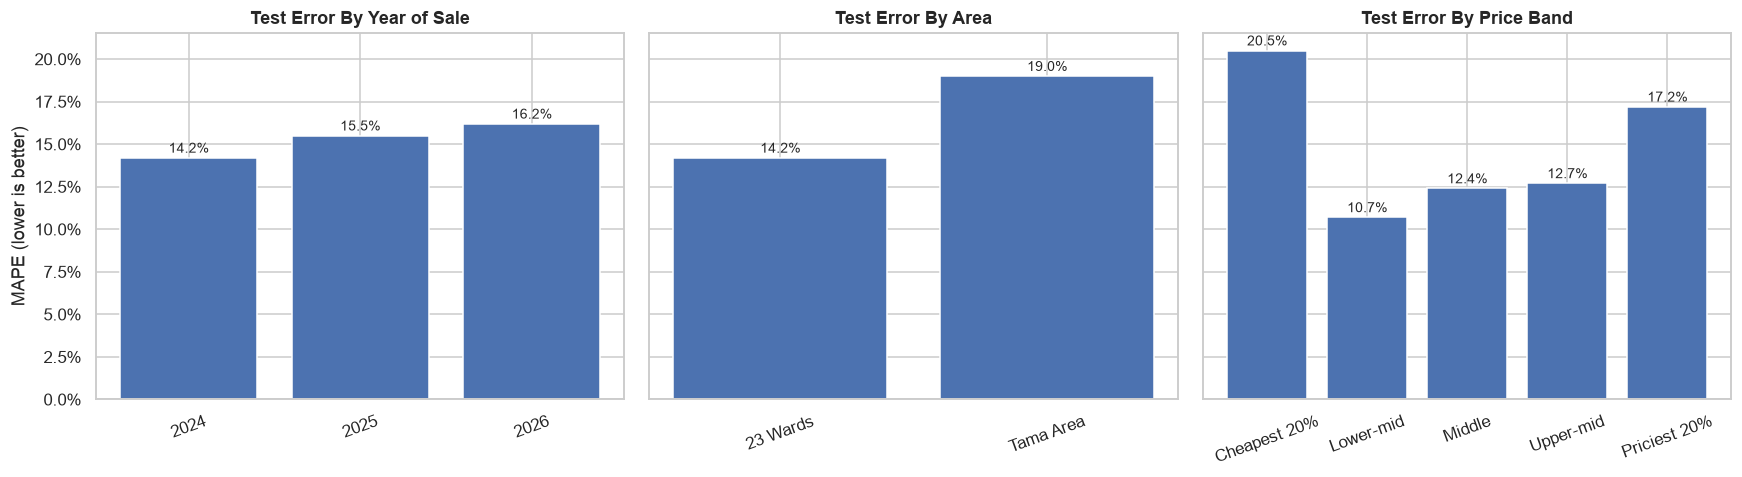

In [3]:
test_df["price_band"] = pd.qcut(test_df["price_yen"], 5,
                                labels=["Cheapest 20%", "Lower-mid", "Middle", "Upper-mid", "Priciest 20%"])


def error_summary(group_col):
    return (test_df.groupby(group_col, observed=True)
                   .agg(sales=("price_yen", "size"), mape=("abs_error_pct", "mean"),
                        median_signed_error=("error_pct", "median"))
                   .round(1))


by_year, by_area, by_band = error_summary("trade_year"), error_summary("area_group"), error_summary("price_band")
display(by_year, by_area, by_band)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (title, table) in zip(axes, [("By Year of Sale", by_year), ("By Area", by_area),
                                     ("By Price Band", by_band)]):
    ax.bar(table.index.astype(str), table["mape"], color="#4C72B0")
    for x, value in enumerate(table["mape"]):
        ax.text(x, value + 0.3, f"{value:.1f}%", ha="center", fontsize=9)
    ax.set_title(f"Test Error {title}")
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("MAPE (lower is better)")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
fig.tight_layout()
fig.savefig(f"{IMAGE_DIR}/14_error_by_segment.png", bbox_inches="tight", dpi=130)
plt.show()

- **By year:** Prediction error increased slightly from 14.2% in 2024 to 16.2% in 2026. The model also continued to under-predict recent sales, with median errors ranging from −2.9% to −6.2%. This suggests that property prices may have increased slightly faster than the market trend used by the model.
- **By area:** The model performs better in the 23 wards, with a MAPE of 14.2%, compared with 19.0% in the Tama Area. This may be due to fewer transactions and greater variation in property locations across Tama municipalities.
- **By price band:** The model is most accurate for mid-priced properties, with MAPE ranging from 10.7% to 12.7%. It tends to overestimate the cheapest flats (+6.2%) and underestimate the most expensive ones (−14.7%), pulling predictions towards the middle of the price range.

**What this means:** The model is most reliable when estimating prices for typical resale flats. Predictions for very low-priced or luxury properties should be treated with caution, as the model is less accurate at both ends of the market.

## 3. Feature Importance (Permutation)

,label,mape_increase,std
0,Floor area,52.58,0.64
2,Building age,19.52,0.38
9,Municipality,11.44,0.16
15,Nearest station,6.06,0.13
3,Walk to station,2.48,0.06
12,Renovation,2.22,0.05
14,District,2.05,0.04
6,Floor-area ratio,1.11,0.02
4,Sale date,0.52,0.02
7,Living + dining room,0.52,0.02


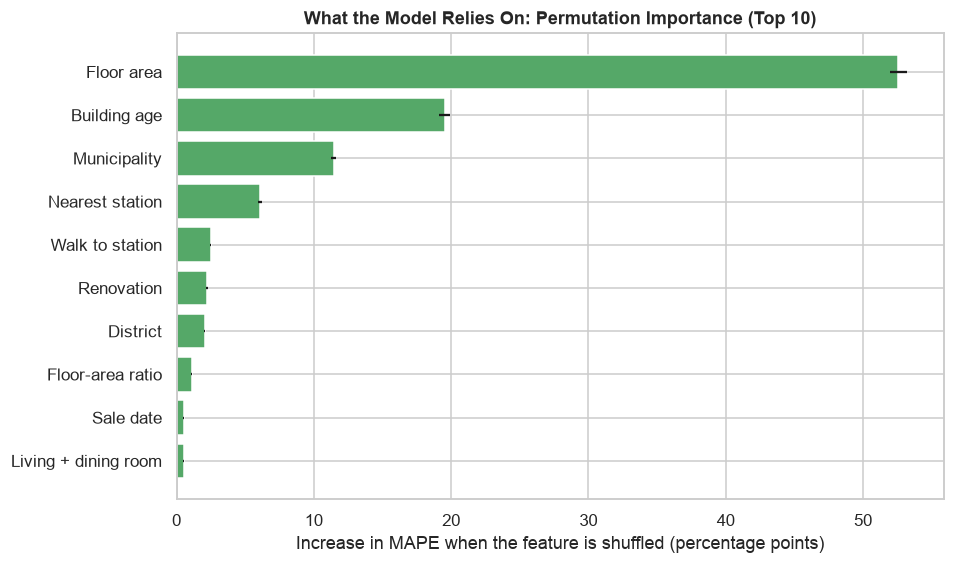

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
importance_sample = test_df.sample(10_000, random_state=RANDOM_STATE)
base_mape = np.mean(np.abs(predict_price(importance_sample) / importance_sample["price_yen"] - 1)) * 100

rows = []
for feature in ALL_FEATURES:
    increases = []
    for _ in range(5):                                   # 5 shuffles per feature, averaged
        shuffled = importance_sample.copy()
        shuffled[feature] = rng.permutation(shuffled[feature].to_numpy())
        new_mape = np.mean(np.abs(predict_price(shuffled) / shuffled["price_yen"] - 1)) * 100
        increases.append(new_mape - base_mape)
    rows.append({"feature": feature, "mape_increase": np.mean(increases), "std": np.std(increases)})

FEATURE_LABELS = {"area_sqm": "Floor area", "building_age": "Building age", "municipality": "Municipality",
                  "nearest_station_jp": "Nearest station", "walk_min": "Walk to station",
                  "renovation": "Renovation", "district_jp": "District", "floor_area_ratio_pct": "Floor-area ratio",
                  "time_index": "Sale date", "has_living_dining": "Living + dining room", "zoning": "Zoning",
                  "rooms": "Rooms", "structure": "Structure", "coverage_ratio_pct": "Coverage ratio",
                  "use_recorded": "Use recorded", "has_storage_room": "Storage room"}
importance = pd.DataFrame(rows).sort_values("mape_increase", ascending=False)
importance["label"] = importance["feature"].map(FEATURE_LABELS)
display(importance[["label", "mape_increase", "std"]].round(2))

top = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top["label"], top["mape_increase"], xerr=top["std"], color="#55A868")
ax.set_title("What the Model Relies On: Permutation Importance (Top 10)")
ax.set_xlabel("Increase in MAPE when the feature is shuffled (percentage points)")
fig.savefig(f"{IMAGE_DIR}/15_feature_importance.png", bbox_inches="tight", dpi=130)
plt.show()

Permutation importance measures how much a model's prediction error increases when a feature is randomly shuffled, breaking its relationship with the target variable. I calculated it using the test dataset, with a sample of 10,000 transactions and five repeats for each feature.

The results show the following:

- **Floor area:** By far the most important feature. Shuffling it increases MAPE by 52.6 percentage points.
- **Building age:** The second most important feature, increasing MAPE by 19.5 percentage points.
- **Location:** Also plays a major role. Municipality (+11.4 points), nearest station (+6.1 points) and district (+2.1 points) contribute a combined increase of approximately 19.6 percentage points, similar to building age.
- **Walking time:** Has a measurable impact, increasing MAPE by 2.5 percentage points.
- **Renovation:** Also contributes to predictions, with a 2.2 percentage-point increase in MAPE when shuffled.
- **Sale date:** Has relatively low importance (+0.5 points) because the market trend is handled separately from the tree-based model.
- **Number of rooms:** Adds very little predictive value once floor area is included, which is consistent with the strong correlation between these two features.

**What this means:** Floor area, building age and location are the main factors the model relies on when estimating property prices. The results also show that detailed location information matters, while some features, such as the number of rooms, provide limited additional value once related property characteristics are already known.

## 4. What-If Analysis: How Each Factor Moves the Price


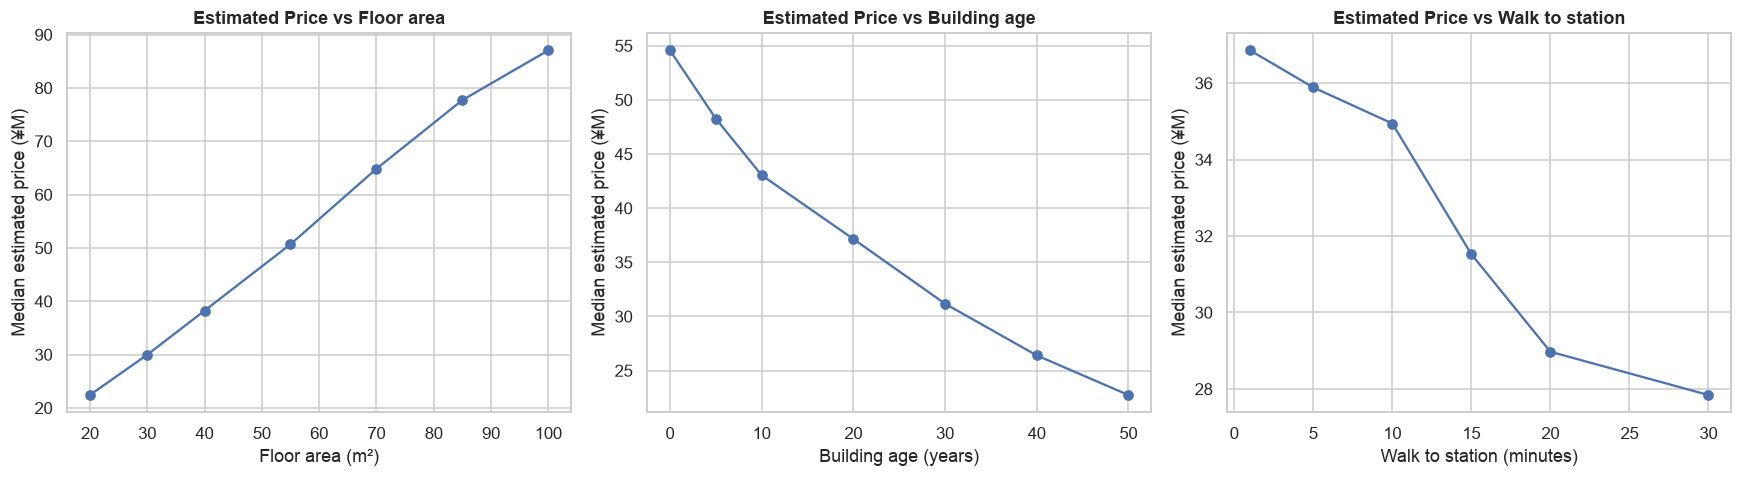

Floor area (m²) → % change vs first value: {20: 0.0, 30: 33.7, 40: 70.5, 55: 126.1, 70: 189.3, 85: 246.7, 100: 288.4}
Building age (years) → % change vs first value: {0: 0.0, 5: -11.6, 10: -21.1, 20: -31.9, 30: -42.9, 40: -51.6, 50: -58.3}
Walk to station (minutes) → % change vs first value: {1: 0.0, 5: -2.6, 10: -5.2, 15: -14.5, 20: -21.4, 30: -24.5}


In [5]:
what_if_sample = test_df.sample(3_000, random_state=RANDOM_STATE)


def what_if(feature, values):
    """Set one feature to each value for every flat in the sample; return the median estimated price."""
    medians = []
    for value in values:
        scenario = what_if_sample.copy()
        scenario[feature] = value
        medians.append(np.median(predict_price(scenario)))
    return pd.Series(medians, index=values)


curves = {"Floor area (m²)": what_if("area_sqm", [20, 30, 40, 55, 70, 85, 100]),
          "Building age (years)": what_if("building_age", [0, 5, 10, 20, 30, 40, 50]),
          "Walk to station (minutes)": what_if("walk_min", [1, 5, 10, 15, 20, 30])}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (label, curve) in zip(axes, curves.items()):
    ax.plot(curve.index, curve.values / 1e6, marker="o", color="#4C72B0")
    ax.set_title(f"Estimated Price vs {label.split(' (')[0]}")
    ax.set_xlabel(label)
    ax.set_ylabel("Median estimated price (¥M)")
fig.tight_layout()
fig.savefig(f"{IMAGE_DIR}/16_what_if_curves.png", bbox_inches="tight", dpi=130)
plt.show()

for label, curve in curves.items():
    print(label, "→ % change vs first value:", (curve / curve.iloc[0] * 100 - 100).round(1).to_dict())

For each scenario, I fixed one feature at a specific value across a sample of 3,000 flats and recorded the median estimated price, keeping all other features unchanged.

- **Walking time:** Prices decrease by only 5% between a 1-minute and a 10-minute walk. Beyond 10 minutes, the decline becomes much sharper: prices are 14.5% lower at 15 minutes and 24.5% lower at 30 minutes. This suggests a clear price drop beyond the 10-minute mark.
- **Building age:** Estimated prices fall by 21% after 10 years, 43% after 30 years and 58% after 50 years. The steepest decline occurs during the first 10 years.
- **Floor area:** Increasing the floor area from 20 m² to 55 m² raises the estimated price by 126%, slightly less than a proportional increase.
- **Renovation:** For flats aged 30 years or more, the median estimated price increases from ¥24.0M to ¥32.0M (+33%) when renovation is applied. This is higher than the 17.1% found for 31–40-year-old flats in Notebook 1 (15.8% overall). I interpret this as an indication that renovation may have a greater impact on older properties, rather than a guaranteed return on renovation costs.

**What this means:** The model highlights three particularly important patterns: prices decline more sharply beyond a 10-minute walk to a station, building age has a substantial impact on value, and renovation can make a meaningful difference for older properties. These are model-based estimates, not guaranteed market outcomes.

In [6]:
# Renovation what-if for older flats (30+ years)
older = what_if_sample[what_if_sample["building_age"] >= 30]
estimates = {}
for status in ["Not renovated", "Renovated"]:
    scenario = older.copy()
    scenario["renovation"] = status
    estimates[status] = np.median(predict_price(scenario))
print(f"30+ year-old flats ({len(older)}): not renovated ¥{estimates['Not renovated'] / 1e6:.1f}M → "
      f"renovated ¥{estimates['Renovated'] / 1e6:.1f}M ({(estimates['Renovated'] / estimates['Not renovated'] - 1) * 100:+.0f}%)")

30+ year-old flats (880): not renovated ¥24.0M → renovated ¥32.0M (+33%)


## 5. Actionable Output: Flagging Over- and Under-Priced Sales


,share of sales (%)
valuation,
Within ±20% of estimate,75.30
Paid >20% above estimate,14.00
Paid >20% below estimate,10.80


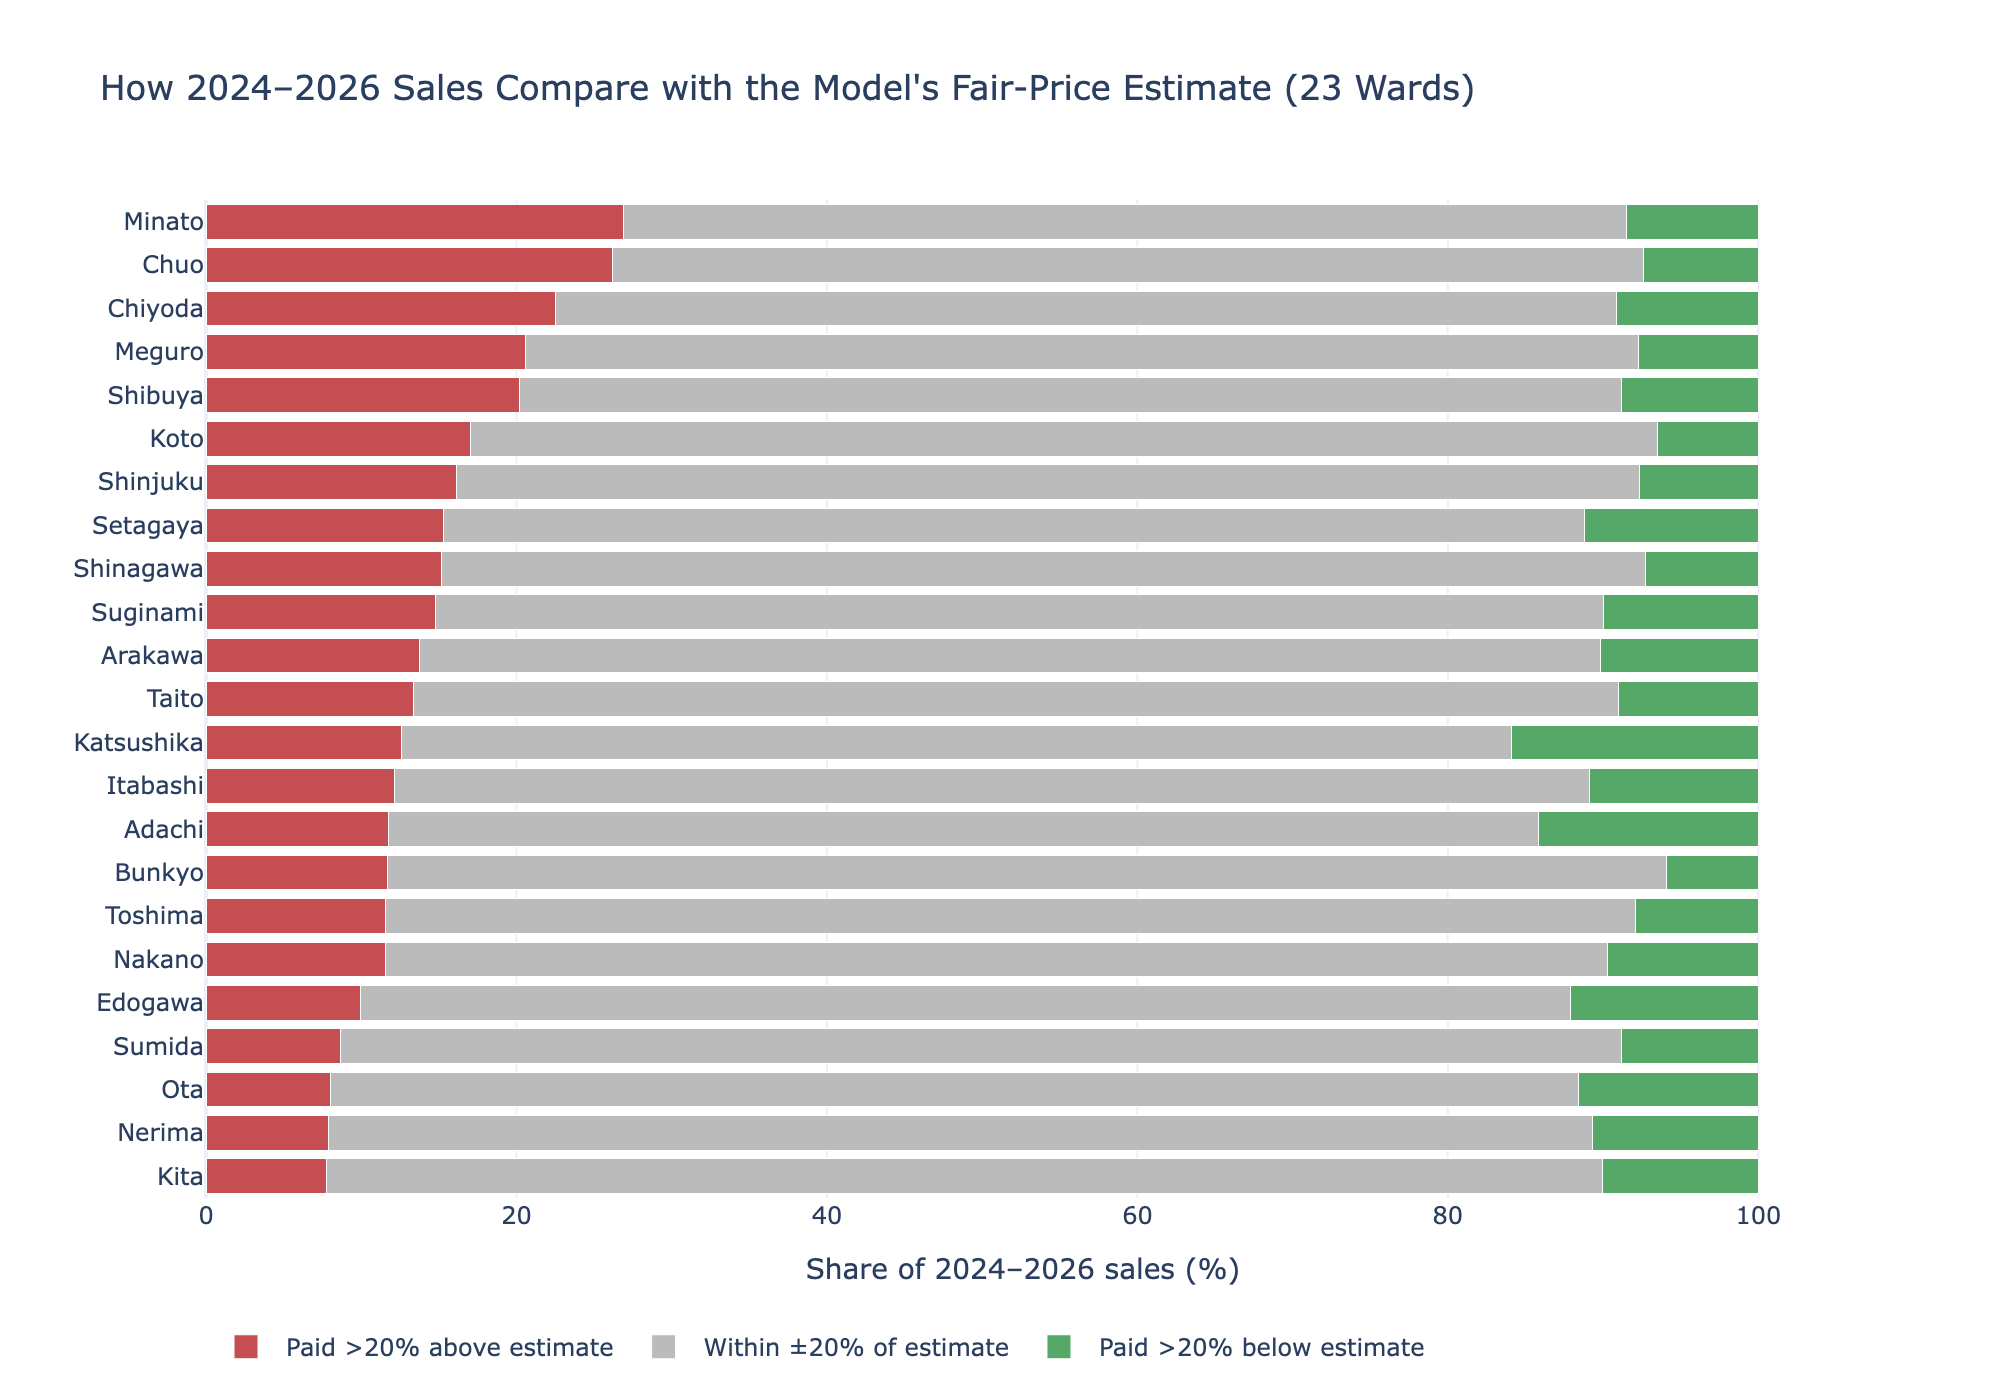

In [7]:
FLAG_THRESHOLD = 20   # % gap between sale price and estimate that counts as "unusual"
labels = [f"Paid >{FLAG_THRESHOLD}% above estimate", f"Within ±{FLAG_THRESHOLD}% of estimate",
          f"Paid >{FLAG_THRESHOLD}% below estimate"]
test_df["valuation"] = np.select([test_df["error_pct"] < -FLAG_THRESHOLD, test_df["error_pct"] > FLAG_THRESHOLD],
                                 [labels[0], labels[2]], default=labels[1])
display(test_df["valuation"].value_counts(normalize=True).mul(100).round(1).to_frame("share of sales (%)"))

ward_flags = (test_df[test_df["area_group"] == "23 Wards"]
              .groupby("municipality")["valuation"].value_counts(normalize=True)
              .mul(100).rename("share_pct").reset_index())
ward_order = (ward_flags[ward_flags["valuation"] == labels[0]]
              .sort_values("share_pct", ascending=False)["municipality"].tolist())

fig = px.bar(ward_flags, x="share_pct", y="municipality", color="valuation", orientation="h",
             category_orders={"municipality": ward_order, "valuation": labels},
             color_discrete_sequence=["#C44E52", "#BBBBBB", "#55A868"],
             labels={"share_pct": "Share of 2024–2026 sales (%)", "municipality": "", "valuation": ""},
             title="How 2024–2026 Sales Compare with the Model's Fair-Price Estimate (23 Wards)")
fig.update_layout(template="plotly_white", barmode="stack", legend=dict(orientation="h", y=-0.12))
show_plotly(fig, "17_valuation_flags_by_ward", height=700)

This provides a practical way to use the model: compare a property's actual sale or asking price with its estimated fair market value. If the difference is greater than 20% in either direction, the property is flagged for further review.

Across sales from 2024–2026, 75.3% were within ±20% of the model's estimate. Meanwhile, 14.0% sold for more than 20% above the estimate, and 10.8% sold for more than 20% below it.

The highest proportions of above-estimate sales were found in the central wards of Minato (26.9%), Chuo (26.2%) and Chiyoda (22.5%). This reflects the premium nature of these markets, as well as the model's tendency to underestimate prices for luxury properties.

The highest proportions of below-estimate sales were recorded in Katsushika (15.9%), Adachi (14.2%) and Edogawa (12.1%). These areas may offer opportunities to find relatively good-value properties, although some of the lower prices could also be due to property-specific issues not captured in the dataset.

**What this means:** The model can help buyers and analysts identify properties that may be worth investigating further. However, a price flagged as unusually high or low should be treated as a starting point for further research, not proof that a property is overpriced or undervalued.

## 6. Key Findings and Recommendations

### For Buyers
- Compare a property's asking price with the model's estimated value. If it is more than 20% higher, consider investigating the difference or negotiating the price.
- Prioritise flats within a 10-minute walk of a railway station, as prices tend to fall more sharply beyond that distance.
- Consider older renovated flats, which may offer good value compared with newer properties.
- Explore Katsushika, Adachi and Edogawa, which have the highest shares of sales below the model's estimated value.

### For Sellers
- Use the model's estimate as a reference when setting the asking price. Around three out of four recent sales were within ±20% of the estimated value.
- For flats more than 20 years old, renovation is associated with a noticeably higher price per m².
- Above-estimate sales are more common in central wards, but sellers should not assume the same premium will apply in other areas.

### For Lenders and Investors
- Use the model as a quick, consistent second opinion when assessing property valuations. Its typical prediction error is approximately 11%.
- Apply additional caution when evaluating luxury properties, very low-priced flats and properties in the Tama Area, where prediction accuracy is lower.
- Consider the longer-term market trend: property prices have increased by approximately 5% per year since 2015, with stronger growth in the 23 wards.

## 7. Limitations

- **Limited property coverage:** The model is designed for typical residential properties. Luxury and distressed sales were removed during outlier treatment, so the model may not perform well for these segments.
- **Variation in prediction accuracy:** The model is less accurate for the cheapest and most expensive flats, as well as properties in the Tama Area.
- **Market trend assumptions:** The model assumes that the market trend observed during 2015–2023 will continue. Any slowdown or acceleration in property prices could affect prediction accuracy.
- **Missing property details:** Important factors such as floor level, property views, building condition and management fees are not available in the dataset.
- **Data limitations:** MLIT rounds transaction prices and floor areas, while location information is available only at the district level. This limits the level of detail the model can capture.
- **Valuation flags are indicative:** A difference between the actual price and the model's estimate does not prove that a property is overpriced or underpriced. It simply highlights transactions that may require further investigation.

## 8. Next Steps

- **Expand data sources:** Incorporate additional datasets, such as station passenger numbers from MLIT's National Land Numerical Information, to capture differences in station activity and accessibility.
- **Improve model performance:** Run a wider hyperparameter search and experiment with additional algorithms, including XGBoost and LightGBM.
- **Keep the model up to date:** Retrain the model quarterly to ensure that the market-trend adjustment reflects the latest property-price movements.
- **Add more property features:** Include factors such as distance from central Tokyo and more detailed building-level information to improve prediction accuracy.
- **Develop a web application:** Build a simple tool where users can enter a property's details and receive an estimated fair-price range.